# One-hidden-layer neural network from scratch — Report

**Course:** Mathematics for Machine Learning · **Author:** Giovanni Piardi

This notebook is the report for the project. It covers:

* **The maths** (Section 1): forward pass, losses, the backpropagation derivation, the optimizers, and the design choices I made.
* **A gradient check** (Section 3): the gradients from backpropagation compared against a finite-difference estimate.
* **The required demonstrations**: the regressor on `load_diabetes` (Section 4) and the binary classifier on `load_breast_cancer` (Section 5).
* **Bonus, multi-class** (Section 6): softmax output on `load_digits` and `load_iris`.
* **Datasets of my choice** (Section 7): California Housing (a real dataset that is also a classic Kaggle one) and the two-moons problem, used to visualise decision boundaries.
* **Design experiments** (Section 8): optimizer, batch size, weight initialisation and target scaling.
* **A summary and conclusions** (Section 9), comparing everything with scikit-learn.

Every comparison with scikit-learn uses an `MLPClassifier`/`MLPRegressor` **configured identically** to my model: the same hidden size, activation, solver, learning rate, batch size, epochs and stopping rule (translated to scikit-learn's conventions, see `sklearn_twin`), with `alpha=0` because my model has no L2 penalty. Scores are the **mean ± std over 5 random seeds**. The seed controls the weight initialisation, the mini-batch shuffling and the early-stopping split. The train/test split is fixed.

| File | Content |
|---|---|
| `activations.py` | identity, logistic, tanh, ReLU (each with its derivative) and softmax |
| `slp_base.py` | shared code: validation, initialisation, training loop, SGD/Adam, backprop of the hidden layer, early stopping |
| `slp_classifier.py` | `SimpleSLPClassifier`: sigmoid (binary) or softmax (multi-class) output, cross-entropy |
| `slp_regressor.py` | `SimpleSLPRegressor`: linear output, MSE, internal target standardisation |
| `tests/` | the 3 provided test files plus `test_extra.py` (gradient check, optimizers, early stopping, validation) |

## 1. The model

### 1.1 Shapes and forward pass

With $n$ samples, $d$ features, $h$ hidden units and $k$ outputs:

| Quantity | Shape | | Quantity | Shape |
|---|---|---|---|---|
| $X$ | $n \times d$ | | $W_2$ | $h \times k$ |
| $W_1$ | $d \times h$ | | $b_2$ | $k$ |
| $b_1$ | $h$ | | $z_2,\ \hat Y$ | $n \times k$ |
| $z_1,\ a_1$ | $n \times h$ | | | |

$$
z_1 = X W_1 + b_1, \qquad a_1 = g(z_1), \qquad z_2 = a_1 W_2 + b_2, \qquad \hat Y = \phi(z_2)
$$

$g$ is the hidden activation and $\phi$ is the output activation. Each row of $X$ is one sample, so a single matrix product processes the whole mini-batch at once. The bias vectors are broadcast over the rows.

| Hidden activation $g$ | $g(z)$ | $g'(z)$ |
|---|---|---|
| identity | $z$ | $1$ |
| logistic | $\sigma(z) = \frac{1}{1+e^{-z}}$ | $\sigma(z)\,(1-\sigma(z))$ |
| tanh | $\tanh z$ | $1-\tanh^2 z$ |
| ReLU | $\max(0, z)$ | $\mathbb 1[z>0]$ (I use $g'(0)=0$) |

### 1.2 Output layer and loss

| Task | $k$ | Output $\phi$ | Loss (mean over the batch) |
|---|---|---|---|
| Regression | number of targets | identity | $L = \frac{1}{nk}\sum_{i,j}(\hat y_{ij}-y_{ij})^2$ (MSE) |
| Binary classification | 1 | sigmoid, $\hat y = P(y=1)$ | $L = -\frac1n\sum_i \big[y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\big]$ |
| Multi-class (bonus) | number of classes | softmax | $L = -\frac1n\sum_i\sum_c y_{ic}\log \hat y_{ic}$ (one-hot $y$) |

For numerical stability, the logistic function clips $z$ to $[-500, 500]$ before calling `exp`. Softmax subtracts each row's maximum first, which leaves the result unchanged because $\mathrm{softmax}(z) = \mathrm{softmax}(z - c)$. The cross-entropy clips $\hat y$ to $[\varepsilon, 1-\varepsilon]$, so it never evaluates $\log 0$.

### 1.3 Backpropagation

Backpropagation is the chain rule applied layer by layer, from the output back to the input. Write $\delta_2 = \partial L/\partial z_2$ for the output error and $\delta_1 = \partial L/\partial z_1$ for the hidden-layer error.

**Step 1: output error.** The loss and output activation were chosen so that the derivative simplifies:

* **Sigmoid + binary cross-entropy.** For one sample, $\frac{\partial L}{\partial \hat y} = \frac{\hat y - y}{\hat y(1-\hat y)}$ and $\frac{\partial \hat y}{\partial z} = \hat y(1-\hat y)$. Their product is $\hat y - y$.
* **Softmax + cross-entropy.** Here $\frac{\partial \hat y_c}{\partial z_j} = \hat y_c(\mathbb 1[c=j]-\hat y_j)$, so $\frac{\partial L}{\partial z_j} = -\sum_c y_c(\mathbb 1[c=j]-\hat y_j) = \hat y_j\sum_c y_c - y_j = \hat y_j - y_j$, using $\sum_c y_c = 1$.
* **Identity + MSE.** $\frac{\partial L}{\partial z_2} = \frac{2}{nk}(\hat Y - Y)$.

Because the loss is a mean, both classification cases give the same formula, $\delta_2 = \frac1n(\hat Y - Y)$.

**Step 2: output-layer gradients.** $\dfrac{\partial L}{\partial W_2} = a_1^\top \delta_2$ and $\dfrac{\partial L}{\partial b_2} = \sum_i \delta_{2,i}$ (column sums).

**Step 3: hidden-layer error.** $\delta_1 = (\delta_2 W_2^\top) \odot g'(z_1)$, where $\odot$ is the element-wise product.

**Step 4: hidden-layer gradients.** $\dfrac{\partial L}{\partial W_1} = X^\top \delta_1$ and $\dfrac{\partial L}{\partial b_1} = \sum_i \delta_{1,i}$.

The gradient of a mean loss is a sum over samples, and the matrix product $a_1^\top\delta_2$ computes exactly that sum. So the code needs no loop over samples or weights. Steps 2–4 are identical for both models and live in `BaseSLPEstimator._gradients_from_output_delta`. Each model only computes its own $\delta_2$.

### 1.4 Optimizers

With learning rate $\eta$ and gradient $\nabla$ of one mini-batch:

* **SGD with momentum** (`solver="sgd"`): $v \leftarrow \mu v - \eta\nabla$, then $w \leftarrow w + v$. Setting `momentum=0` gives plain SGD, $w \leftarrow w - \eta\nabla$.
* **Adam** (`solver="adam"`, the default):
  * $m \leftarrow \beta_1 m + (1-\beta_1)\nabla$ and $s \leftarrow \beta_2 s + (1-\beta_2)\nabla^2$
  * $\hat m = m/(1-\beta_1^t)$ and $\hat s = s/(1-\beta_2^t)$
  * $w \leftarrow w - \eta\,\hat m/(\sqrt{\hat s}+\epsilon)$

  I use $\beta_1=0.9$, $\beta_2=0.999$ and $\epsilon=10^{-8}$. Adam gives every weight its own step size of roughly $\eta$, whatever the scale of its gradient.

### 1.5 Training loop and stopping

One iteration (`max_iter` counts these) is one **epoch**. In each epoch I shuffle the samples, cut them into mini-batches of `batch_size` (default `"auto"` = min(200, n)), and for each mini-batch run forward → loss → backward → update. `batch_size=1` is pure SGD and `batch_size >= n` is full-batch gradient descent. `loss_curve_` stores the mean loss of each epoch.

Training stops after `max_iter` epochs, or earlier when the monitored loss has not improved by at least `tol` for `n_iter_no_change` consecutive epochs:

* With `early_stopping=False`, the monitored loss is the **training** loss (the convergence check, the same rule as scikit-learn).
* With `early_stopping=True`, it is the **validation** loss on `validation_fraction` of the training data, held out. At the end the weights from the best validation epoch are **restored**.

If `max_iter` is reached first, a `ConvergenceWarning` is raised.

### 1.6 Design choices (each one is tested in Section 8)

1. **Glorot/Xavier initialisation instead of $\mathcal N(0, 0.01^2)$.** $W \sim U(-r, r)$ with $r=\sqrt{6/(\text{fan-in}+\text{fan-out})}$, or $\sqrt{2/\ldots}$ for the logistic activation, which is the same scheme scikit-learn uses. With weights of size 0.01, every $z_1$ is close to 0, so all hidden units start almost identical. The gradient of $W_1$ is also proportional to $W_2 \approx 0.01$, so learning starts slowly. Biases are drawn from the same uniform distribution as the weights, as in scikit-learn.
2. **Adam is the default solver.** The provided tests train with `learning_rate=0.001` for 100–300 epochs. At that learning rate plain SGD barely moves, and it fails one of the provided tests (Section 8.1). Adam is also scikit-learn's default. SGD with momentum is available with `solver="sgd"`.
3. **The regressor standardises the targets internally.** It stores `y_mean_` and `y_scale_` and maps predictions back to the original units. The project tips recommend standardising continuous targets, and doing it inside `fit` means a user cannot forget. R² is unaffected.
4. **Binary classification uses one sigmoid unit** (`n_outputs_ = 1`), as the brief asks and as scikit-learn does. With more than two classes the output becomes a softmax over $k$ units. `predict_proba` always returns one column per class.

## 2. Setup

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import (
    fetch_california_housing, load_breast_cancer, load_diabetes, load_digits,
    load_iris, make_classification, make_moons, make_regression,
)
from sklearn.exceptions import ConvergenceWarning as SklearnConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler

from slp_base import ConvergenceWarning
from slp_classifier import SimpleSLPClassifier
from slp_regressor import SimpleSLPRegressor

# Several experiments stop at max_iter on purpose; the number of epochs is reported instead.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=SklearnConvergenceWarning)

SEEDS = range(5)

# Plot style: one fixed colour per entity (ours = blue, sklearn = orange), recessive grid/axes.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OURS, SKLEARN = SERIES[0], SERIES[1]
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_2,
    "axes.prop_cycle": cycler(color=SERIES), "figure.dpi": 110, "font.size": 10,
})
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fe", "#86b6ef", "#2a78d6", "#0d366b"])
BLUE_RED = LinearSegmentedColormap.from_list("blue_red", ["#2a78d6", "#f0efec", "#e34948"])

In [2]:
def split_and_scale(X, y, stratify=False, test_size=0.2):
    # Fixed train/test split; the scaler is fitted on the training set only (no leakage).
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=0, stratify=y if stratify else None
    )
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test), y_train, y_test


def sklearn_twin(ours):
    # An sklearn MLP with exactly the same hyper-parameters as our (fitted or unfitted) model.
    p = ours.get_params()
    # Same stopping rule, translated to sklearn's conventions: sklearn stops when the number of
    # epochs without improvement EXCEEDS n_iter_no_change (we stop when it reaches it), and its
    # regression loss is MSE / 2, so the same improvement in MSE is tol / 2 in sklearn's units.
    patience = max(p["n_iter_no_change"] - 1, 1)
    tol = p["tol"] / 2 if isinstance(ours, SimpleSLPRegressor) else p["tol"]
    kwargs = dict(
        hidden_layer_sizes=(p["hidden_layer_size"],), activation=p["activation"],
        solver=p["solver"], learning_rate_init=p["learning_rate"],
        momentum=p["momentum"], nesterovs_momentum=False, batch_size=p["batch_size"],
        max_iter=p["max_iter"], early_stopping=p["early_stopping"],
        validation_fraction=p["validation_fraction"], n_iter_no_change=patience,
        tol=tol, random_state=p["random_state"],
        alpha=0.0,  # no L2 penalty, like our model
    )
    if isinstance(ours, SimpleSLPClassifier):
        return MLPClassifier(**kwargs)
    # Our regressor standardises y internally; give sklearn the same treatment.
    return TransformedTargetRegressor(regressor=MLPRegressor(**kwargs), transformer=StandardScaler())


def sklearn_network(model):
    return model.regressor_ if isinstance(model, TransformedTargetRegressor) else model


def fit_timed(model, X, y):
    start = time.perf_counter()
    model.fit(X, y)
    return time.perf_counter() - start


def compare(model_class, params, data, seeds=SEEDS):
    # Fit our model and its sklearn twin once per seed; return a per-seed table and the fitted models.
    X_train, X_test, y_train, y_test = data
    rows, models = [], []
    for seed in seeds:
        ours = model_class(**params, random_state=seed)
        theirs = sklearn_twin(ours)
        time_ours, time_theirs = fit_timed(ours, X_train, y_train), fit_timed(theirs, X_train, y_train)
        rows.append({
            "score ours": ours.score(X_test, y_test), "score sklearn": theirs.score(X_test, y_test),
            "time ours": time_ours, "time sklearn": time_theirs,
            "epochs ours": ours.n_iter_, "epochs sklearn": sklearn_network(theirs).n_iter_,
        })
        models.append((ours, theirs))
    return pd.DataFrame(rows), models


SUMMARY = []


def report(results, dataset, task, metric, baseline_name, baseline):
    # Print mean ± std for one comparison and store it for the final summary table.
    def pm(column, fmt):
        return f"{results[column].mean():{fmt}} ± {results[column].std():{fmt}}"

    table = pd.DataFrame(
        {"ours": [pm("score ours", ".3f"), pm("time ours", ".2f"), f"{results['epochs ours'].mean():.0f}"],
         "sklearn": [pm("score sklearn", ".3f"), pm("time sklearn", ".2f"), f"{results['epochs sklearn'].mean():.0f}"]},
        index=[f"test {metric}", "fit time (s)", "epochs run"],
    )
    SUMMARY.append({
        "dataset": dataset, "task": task, "metric": metric,
        "baseline": f"{baseline:.3f} ({baseline_name})",
        "ours": pm("score ours", ".3f"), "sklearn": pm("score sklearn", ".3f"),
        "fit time ours (s)": f"{results['time ours'].mean():.2f}",
        "fit time sklearn (s)": f"{results['time sklearn'].mean():.2f}",
    })
    print(f"Baseline ({baseline_name}): test {metric} = {baseline:.3f}")
    return table


def plot_loss_curves(ax, ours, theirs, title, ylabel="training loss"):
    sk_curve = np.asarray(sklearn_network(theirs).loss_curve_)
    if isinstance(ours, SimpleSLPRegressor):
        sk_curve = 2 * sk_curve  # sklearn reports MSE / 2; ours is the MSE
    ax.plot(np.arange(1, len(ours.loss_curve_) + 1), ours.loss_curve_, color=OURS, label="ours")
    ax.plot(np.arange(1, len(sk_curve) + 1), sk_curve, color=SKLEARN, linestyle="--", label="sklearn")
    ax.set(title=title, xlabel="epoch", ylabel=ylabel)
    ax.legend()


def plain_log_axis(ax):
    # Log-scale y-axis labelled with plain numbers (0.05, 0.1, 0.2 ...) instead of 10^x notation.
    ax.set_yscale("log")
    low, high = ax.get_ylim()
    candidates = [c * 10.0 ** e for e in range(-4, 2) for c in (1, 2, 5)]
    ax.set_yticks([t for t in candidates if low <= t <= high])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())


def label_line_ends(ax, x, ends, labels, min_gap=0.07):
    # Direct labels at the right end of each line (log y-axis), nudged apart so they never overlap.
    positions = np.log10(ends)
    order = np.argsort(positions)
    placed = positions.copy()
    for previous, current in zip(order[:-1], order[1:]):
        placed[current] = max(placed[current], placed[previous] + min_gap)
    for position, label in zip(placed, labels):
        ax.text(x, 10 ** position, label, color=INK_2, fontsize=8, va="center")


def plot_confusion(ax, y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    ax.imshow(cm, cmap=BLUES)
    ax.grid(False)
    ax.set(title=title, xlabel="predicted", ylabel="true",
           xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=labels, yticklabels=labels)
    for (i, j), count in np.ndenumerate(cm):
        ax.text(j, i, count, ha="center", va="center", fontsize=9,
                color="white" if count > cm.max() / 2 else INK)

## 3. Gradient check: is backpropagation correct?

Before trusting any result, I check that the analytic gradients from backpropagation (Section 1.3) agree with a **numerical** estimate from central finite differences:

$$\frac{\partial L}{\partial w} \approx \frac{L(w+\varepsilon) - L(w-\varepsilon)}{2\varepsilon}, \qquad \varepsilon = 10^{-6}$$

I perturb every weight and bias one at a time and report the relative error $\frac{\lVert g_{\text{backprop}} - g_{\text{numeric}}\rVert}{\lVert g_{\text{backprop}}\rVert + \lVert g_{\text{numeric}}\rVert}$. The worst case over the four parameter arrays is shown. Values around $10^{-8}$ or smaller mean the derivation and the code agree. A sign error or a missing factor would give an error of order $10^{-1}$. The check runs on a small network after 5 epochs of training, so the weights are not at their initial values. The same check is in `tests/test_extra.py`.

In [3]:
def worst_relative_error(model, X, Y, eps=1e-6):
    analytic = model._backward_propagation(X, Y, *model._forward_propagation(X))
    worst = 0.0
    for param, grad in zip(model._parameters(), analytic):
        numeric = np.zeros_like(param)
        for idx in np.ndindex(param.shape):
            original = param[idx]
            param[idx] = original + eps
            loss_plus = model._compute_loss(Y, model._forward_propagation(X)[3])
            param[idx] = original - eps
            loss_minus = model._compute_loss(Y, model._forward_propagation(X)[3])
            param[idx] = original
            numeric[idx] = (loss_plus - loss_minus) / (2 * eps)
        error = np.linalg.norm(grad - numeric) / (np.linalg.norm(grad) + np.linalg.norm(numeric))
        worst = max(worst, error)
    return worst


rng = np.random.default_rng(0)
X_small = rng.normal(size=(12, 4))
y_binary, y_multi, y_continuous = rng.integers(0, 2, 12), rng.integers(0, 3, 12), rng.normal(size=12)

rows = {}
for activation in ["identity", "logistic", "tanh", "relu"]:
    small = dict(hidden_layer_size=5, activation=activation, max_iter=5, learning_rate=0.05, random_state=0)
    binary = SimpleSLPClassifier(**small).fit(X_small, y_binary)
    multi = SimpleSLPClassifier(**small).fit(X_small, y_multi)
    regressor = SimpleSLPRegressor(**small).fit(X_small, y_continuous)
    rows[activation] = {
        "binary (sigmoid + BCE)": worst_relative_error(binary, X_small, binary._encode_targets(y_binary)),
        "multi-class (softmax + CE)": worst_relative_error(multi, X_small, multi._encode_targets(y_multi)),
        "regression (identity + MSE)": worst_relative_error(
            regressor, X_small, ((y_continuous - regressor.y_mean_) / regressor.y_scale_).reshape(-1, 1)),
    }
pd.DataFrame(rows).T.style.format("{:.1e}").set_caption("Worst relative error, backprop vs finite differences")

,binary (sigmoid + BCE),multi-class (softmax + CE),regression (identity + MSE)
identity,7.8e-10,2.2e-09,2.5e-10
logistic,5.6e-09,1.1e-08,5.3e-09
tanh,1.7e-09,1.9e-09,3.9e-10
relu,4.9e-10,1.7e-09,1.6e-10


## 4. Regression on the diabetes dataset (`load_diabetes`)

The dataset has 442 patients and 10 baseline variables: age, sex, BMI, blood pressure and six blood-serum measurements. The target is a measure of disease progression one year later, ranging from 25 to 346. It is a small and noisy problem, so a linear regression is included as a baseline.

**Settings:** 20 hidden units, logistic activation, Adam with learning rate 0.01, and early stopping (10% validation, patience 10, up to 1000 epochs). Section 4.2 shows why early stopping is needed here.

In [4]:
X, y = load_diabetes(return_X_y=True)
diabetes = split_and_scale(X, y)
print(f"train {diabetes[0].shape}, test {diabetes[1].shape}, target range {y.min():.0f}-{y.max():.0f}")

diabetes_params = dict(hidden_layer_size=20, activation="logistic", learning_rate=0.01,
                       max_iter=1000, early_stopping=True)
diabetes_results, diabetes_models = compare(SimpleSLPRegressor, diabetes_params, diabetes)
linear_r2 = LinearRegression().fit(diabetes[0], diabetes[2]).score(diabetes[1], diabetes[3])
report(diabetes_results, "Diabetes", "regression", "R²", "linear regression", linear_r2)

train (353, 10), test (89, 10), target range 25-346
Baseline (linear regression): test R² = 0.332


,ours,sklearn
test R²,0.337 ± 0.022,0.329 ± 0.027
fit time (s),0.01 ± 0.00,0.01 ± 0.01
epochs run,38,40


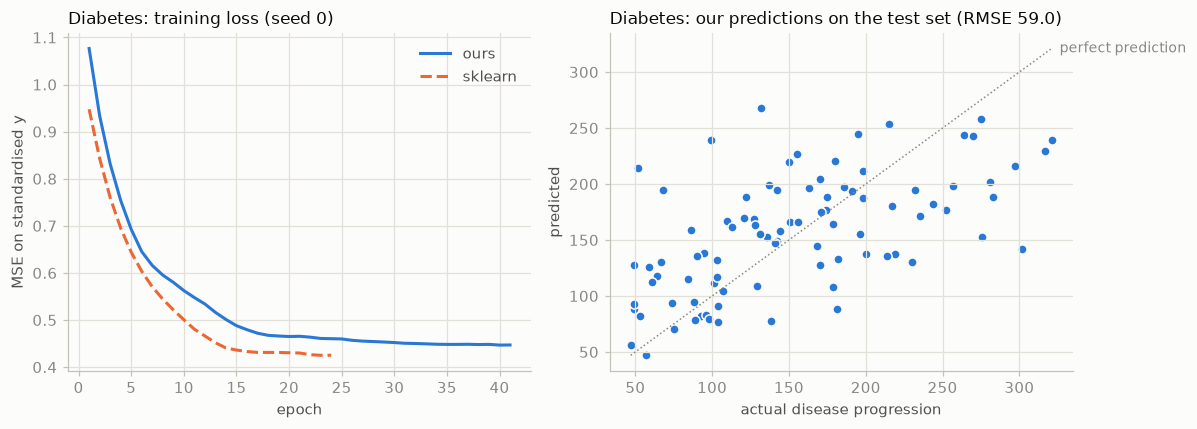

In [5]:
ours, theirs = diabetes_models[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
plot_loss_curves(ax1, ours, theirs, "Diabetes: training loss (seed 0)", "MSE on standardised y")

y_pred = ours.predict(diabetes[1])
ax2.scatter(diabetes[3], y_pred, s=36, color=OURS, edgecolor=SURFACE, linewidth=1)
limits = [min(diabetes[3].min(), y_pred.min()), max(diabetes[3].max(), y_pred.max())]
ax2.plot(limits, limits, color=MUTED, linewidth=1, linestyle=":")
ax2.text(limits[1], limits[1], "  perfect prediction", color=MUTED, fontsize=9, va="center")
rmse = mean_squared_error(diabetes[3], y_pred) ** 0.5
ax2.set(title=f"Diabetes: our predictions on the test set (RMSE {rmse:.1f})",
        xlabel="actual disease progression", ylabel="predicted")
plt.tight_layout()
plt.show()

### 4.2 Why early stopping matters on this dataset

There are only 353 training samples, and the target is noisy. A network trained for many epochs starts to **memorise the noise**: the training loss keeps falling while the validation loss turns back up. Below, the same model is trained for 300 epochs with a patience large enough that it never stops, so both curves are visible in full. The vertical lines mark the epoch with the lowest validation loss and the epoch where early stopping with patience 10 actually stops. Up to that point the two runs are identical, because they use the same seed.

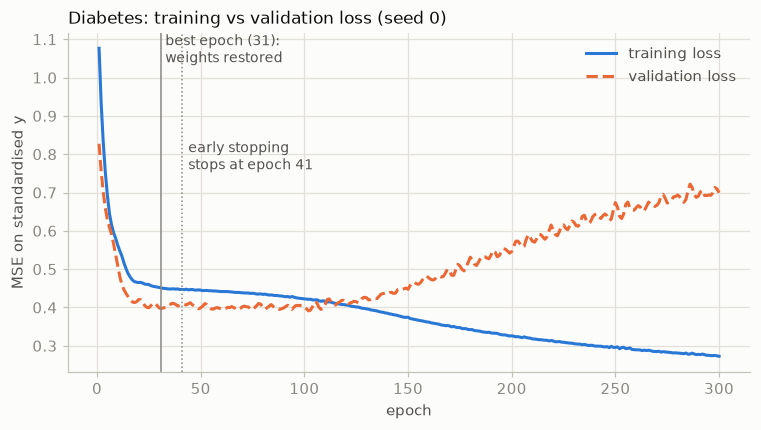

,"test R² (mean ± std, 5 seeds)"
"300 epochs, no early stopping",0.206 ± 0.049
early stopping (patience 10),0.337 ± 0.022


In [6]:
overfit_params = dict(hidden_layer_size=20, activation="logistic", learning_rate=0.01, early_stopping=True)
long_run = SimpleSLPRegressor(**overfit_params, max_iter=300, n_iter_no_change=300, random_state=0)
long_run.fit(diabetes[0], diabetes[2])
early_run = SimpleSLPRegressor(**overfit_params, max_iter=1000, n_iter_no_change=10, random_state=0)
early_run.fit(diabetes[0], diabetes[2])
best_epoch = int(np.argmin(early_run.validation_loss_curve_)) + 1

fig, ax = plt.subplots(figsize=(8, 4))
epochs = np.arange(1, 301)
ax.plot(epochs, long_run.loss_curve_, color=OURS, label="training loss")
ax.plot(epochs, long_run.validation_loss_curve_, color=SKLEARN, linestyle="--", label="validation loss")
ax.axvline(best_epoch, color=MUTED, linewidth=1)
ax.axvline(early_run.n_iter_, color=MUTED, linewidth=1, linestyle=":")
ax.text(best_epoch, ax.get_ylim()[1], f" best epoch ({best_epoch}):\n weights restored", color=INK_2, fontsize=9, va="top")
ax.text(early_run.n_iter_ + 3, ax.get_ylim()[1] * 0.75, f"early stopping\nstops at epoch {early_run.n_iter_}", color=INK_2, fontsize=9, va="top")
ax.set(title="Diabetes: training vs validation loss (seed 0)", xlabel="epoch", ylabel="MSE on standardised y")
ax.legend(loc="upper right")
plt.show()

no_es = [SimpleSLPRegressor(hidden_layer_size=20, learning_rate=0.01, max_iter=300, random_state=s)
         .fit(diabetes[0], diabetes[2]).score(diabetes[1], diabetes[3]) for s in SEEDS]
pd.DataFrame({
    "test R² (mean ± std, 5 seeds)": [f"{np.mean(no_es):.3f} ± {np.std(no_es, ddof=1):.3f}",
                                     f"{diabetes_results['score ours'].mean():.3f} ± {diabetes_results['score ours'].std():.3f}"],
}, index=["300 epochs, no early stopping", "early stopping (patience 10)"])

## 5. Binary classification on the breast cancer dataset (`load_breast_cancer`)

The dataset has 569 tumours, each described by 30 features computed from a digitised image of a fine-needle aspirate. Each tumour is labelled **malignant** (0, 212 cases) or **benign** (1, 357 cases). I use a stratified 80/20 split.

**Settings:** 30 hidden units, logistic activation, a single sigmoid output, Adam with learning rate 0.01, and up to 300 epochs.

In [7]:
data = load_breast_cancer()
cancer = split_and_scale(data.data, data.target, stratify=True)
print(f"train {cancer[0].shape}, test {cancer[1].shape}, classes {list(data.target_names)}")

cancer_params = dict(hidden_layer_size=30, activation="logistic", learning_rate=0.01, max_iter=300)
cancer_results, cancer_models = compare(SimpleSLPClassifier, cancer_params, cancer)
logistic_acc = LogisticRegression(max_iter=1000).fit(cancer[0], cancer[2]).score(cancer[1], cancer[3])
report(cancer_results, "Breast cancer", "binary classification", "accuracy", "logistic regression", logistic_acc)

train (455, 30), test (114, 30), classes [np.str_('malignant'), np.str_('benign')]


Baseline (logistic regression): test accuracy = 0.982


,ours,sklearn
test accuracy,0.982 ± 0.000,0.982 ± 0.000
fit time (s),0.09 ± 0.00,0.10 ± 0.00
epochs run,298,298


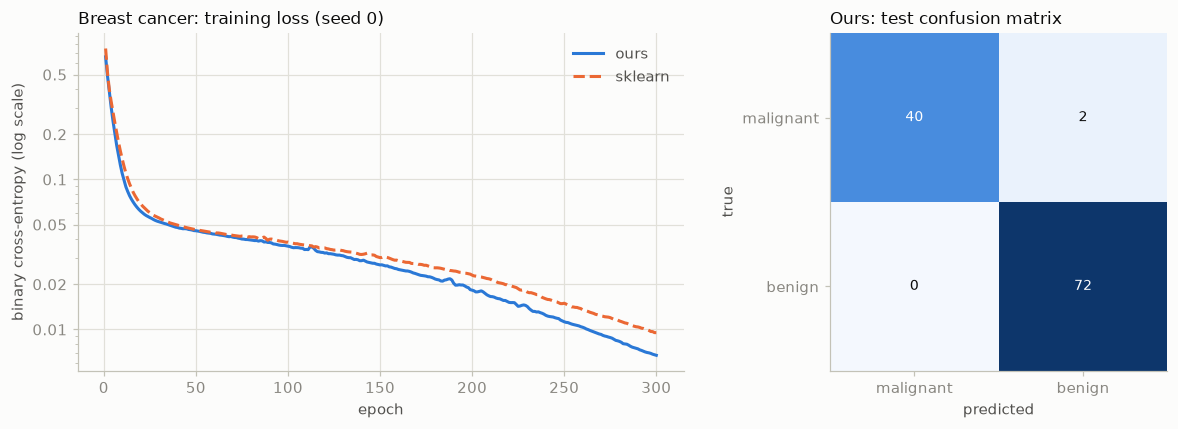

predict_proba shape: (114, 2) | rows sum to 1: True


In [8]:
ours, theirs = cancer_models[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
plot_loss_curves(ax1, ours, theirs, "Breast cancer: training loss (seed 0)", "binary cross-entropy (log scale)")
plain_log_axis(ax1)
plot_confusion(ax2, cancer[3], ours.predict(cancer[1]), list(data.target_names), "Ours: test confusion matrix")
plt.tight_layout()
plt.show()

proba = ours.predict_proba(cancer[1])
print("predict_proba shape:", proba.shape, "| rows sum to 1:", np.allclose(proba.sum(axis=1), 1))

## 6. Bonus: multi-class classification with softmax (`load_digits`, `load_iris`)

With more than two classes, the classifier switches to $k$ softmax outputs and one-hot targets. No other code changes, because $\delta_2 = (\hat Y - Y)/n$ holds in both cases (Section 1.3).

**Digits:** 1,797 handwritten digits, each an 8×8 image (64 pixel features), in 10 classes. **Settings:** 100 hidden units, ReLU, Adam with learning rate 0.001, and up to 300 epochs.

In [9]:
digits_data = load_digits()
digits = split_and_scale(digits_data.data, digits_data.target, stratify=True)
digits_params = dict(hidden_layer_size=100, activation="relu", learning_rate=0.001, max_iter=300)
digits_results, digits_models = compare(SimpleSLPClassifier, digits_params, digits)
logistic_acc = LogisticRegression(max_iter=2000).fit(digits[0], digits[2]).score(digits[1], digits[3])
report(digits_results, "Digits", "10-class classification", "accuracy", "logistic regression", logistic_acc)

Baseline (logistic regression): test accuracy = 0.967


,ours,sklearn
test accuracy,0.976 ± 0.001,0.977 ± 0.004
fit time (s),0.15 ± 0.00,0.23 ± 0.00
epochs run,144,143


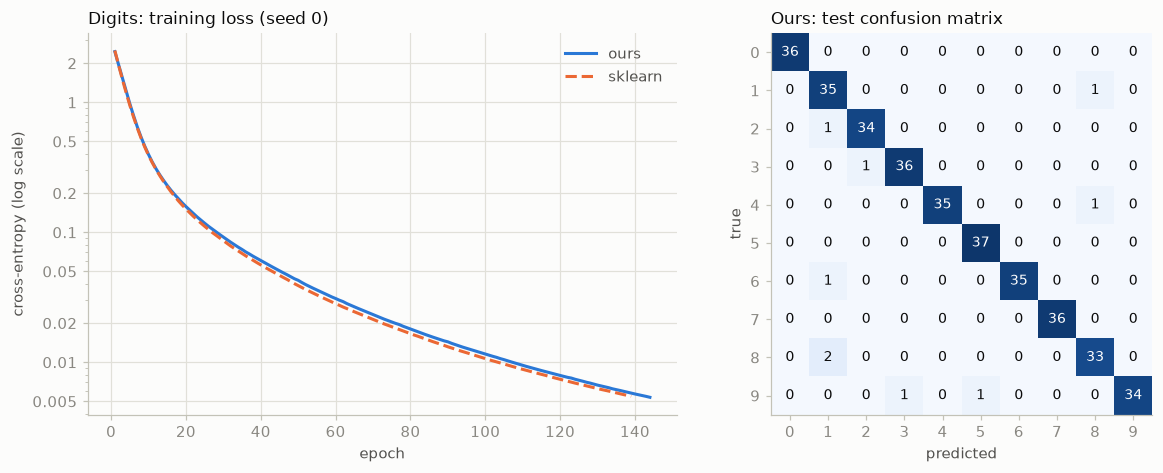

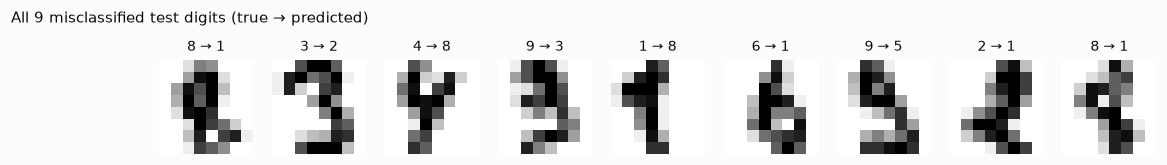

In [10]:
ours, theirs = digits_models[0]
y_pred = ours.predict(digits[1])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
plot_loss_curves(ax1, ours, theirs, "Digits: training loss (seed 0)", "cross-entropy (log scale)")
plain_log_axis(ax1)
plot_confusion(ax2, digits[3], y_pred, list(range(10)), "Ours: test confusion matrix")
plt.tight_layout()
plt.show()

# The test images the network gets wrong (pixels before scaling)
_, raw_test_images = train_test_split(digits_data.images, test_size=0.2, random_state=0, stratify=digits_data.target)
wrong = np.flatnonzero(y_pred != digits[3])
fig, axes = plt.subplots(1, len(wrong), figsize=(1.3 * len(wrong), 1.8), squeeze=False)
for ax, i in zip(axes[0], wrong):
    ax.imshow(raw_test_images[i], cmap="gray_r")
    ax.set_title(f"{digits[3][i]} → {y_pred[i]}", fontsize=9, loc="center")
    ax.axis("off")
fig.suptitle(f"All {len(wrong)} misclassified test digits (true → predicted)", x=0.01, ha="left", fontsize=10, color=INK)
plt.show()

**Iris:** 150 flowers, 4 features, 3 species. **Settings:** 20 hidden units, tanh, Adam with learning rate 0.01, and up to 300 epochs. Iris has only 30 test samples, so each misclassification costs 3.3 points of accuracy.

In [11]:
iris_data = load_iris()
iris = split_and_scale(iris_data.data, iris_data.target, stratify=True)
iris_params = dict(hidden_layer_size=20, activation="tanh", learning_rate=0.01, max_iter=300)
iris_results, iris_models = compare(SimpleSLPClassifier, iris_params, iris)
logistic_acc = LogisticRegression(max_iter=1000).fit(iris[0], iris[2]).score(iris[1], iris[3])
report(iris_results, "Iris", "3-class classification", "accuracy", "logistic regression", logistic_acc)

Baseline (logistic regression): test accuracy = 0.967


,ours,sklearn
test accuracy,1.000 ± 0.000,1.000 ± 0.000
fit time (s),0.01 ± 0.00,0.02 ± 0.00
epochs run,180,197


## 7. Datasets of my choice

### 7.1 California Housing (regression on a real, larger dataset)

The dataset comes from the 1990 US census and has 20,640 districts in California. The target is the median house value in units of \$100,000, and there are 8 features: median income, house age, average rooms and bedrooms, population, average occupancy, latitude and longitude. The same data is the well-known Kaggle dataset *California Housing Prices*. scikit-learn downloads it once and caches it.

It has about 50 times more samples than diabetes, and the relationship is clearly non-linear (location and income interact), so a hidden layer should beat a linear model by a wide margin. **Settings:** 100 hidden units, ReLU, Adam with learning rate 0.001, mini-batches of 200, and up to 200 epochs.

train (16512, 8), test (4128, 8)


Baseline (linear regression): test R² = 0.594


,ours,sklearn
test R²,0.742 ± 0.024,0.774 ± 0.006
fit time (s),1.08 ± 0.23,1.63 ± 0.50
epochs run,135,128


Ours (seed 0): test RMSE = $59,461


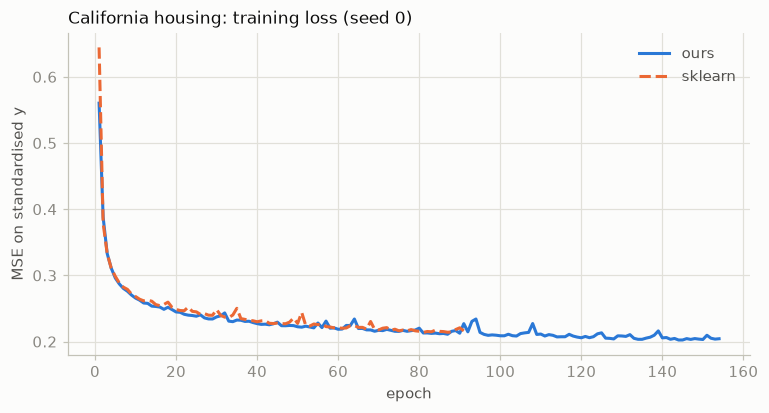

In [12]:
housing_data = fetch_california_housing()
housing = split_and_scale(housing_data.data, housing_data.target)
print(f"train {housing[0].shape}, test {housing[1].shape}")

housing_params = dict(hidden_layer_size=100, activation="relu", learning_rate=0.001, max_iter=200)
housing_results, housing_models = compare(SimpleSLPRegressor, housing_params, housing)
linear_r2 = LinearRegression().fit(housing[0], housing[2]).score(housing[1], housing[3])
display(report(housing_results, "California housing", "regression", "R²", "linear regression", linear_r2))

ours, theirs = housing_models[0]
rmse = mean_squared_error(housing[3], ours.predict(housing[1])) ** 0.5
print(f"Ours (seed 0): test RMSE = ${rmse * 100_000:,.0f}")
fig, ax = plt.subplots(figsize=(8, 3.8))
plot_loss_curves(ax, ours, theirs, "California housing: training loss (seed 0)", "MSE on standardised y")
plt.show()

**Is the gap to scikit-learn real?** Here our mean R² is lower than scikit-learn's and the spread is larger. The training-loss curves overlap, though, which points at the test score rather than at the training. The test set contains districts far outside the training data, with one standardised feature value almost 200 standard deviations from the training mean. A ReLU network extrapolates linearly, so a handful of such points can get extreme predictions and dominate the squared error. How badly that happens depends on the random initialisation. With only 5 seeds this is largely luck, so below I repeat the comparison with **20 seeds** and also compute R² without the 5 worst test predictions.

In [13]:
many_results, many_models = compare(SimpleSLPRegressor, housing_params, housing, seeds=range(20))
X_test_h, y_test_h = housing[1], housing[3]
extreme = np.abs(X_test_h).max(axis=0)
print(f"Most extreme test feature: {housing_data.feature_names[extreme.argmax()]}, "
      f"{extreme.max():.0f} standard deviations from the training mean")


def r2_without_worst(model, k=5):
    pred = model.predict(X_test_h)
    keep = np.argsort(np.abs(pred - y_test_h))[:-k]
    return r2_score(y_test_h[keep], pred[keep])


robust = {}
for name, column, position in [("ours", "score ours", 0), ("sklearn", "score sklearn", 1)]:
    scores = many_results[column]
    robust[name] = {"mean R² (20 seeds)": scores.mean(), "median R²": scores.median(), "worst seed": scores.min(),
                    "mean R² without the 5 worst test points": np.mean([r2_without_worst(m[position]) for m in many_models])}
pd.DataFrame(robust).style.format("{:.3f}")

Most extreme test feature: AveOccup, 193 standard deviations from the training mean


,ours,sklearn
mean R² (20 seeds),0.756,0.760
median R²,0.768,0.772
worst seed,0.666,0.618
mean R² without the 5 worst test points,0.787,0.788


Over 20 seeds the two implementations are indistinguishable, and each has its own bad seeds. Excluding the five worst points brings both to the same R². The remaining weakness is about the data, not the implementation: clipping or log-transforming the heavy-tailed features would make both models more robust.

### 7.2 Two moons: what the hidden layer buys us

`make_moons` produces two interleaving half-circles, 500 points with noise 0.25. No straight line can separate them, so it is a direct test of whether the hidden layer learns a non-linear decision boundary. I train the same network (10 hidden units, Adam with learning rate 0.01, 2000 epochs with the convergence check switched off) with each hidden activation and plot $P(y=1 \mid x)$ over the plane. With the **identity** activation, the network collapses to a linear model, because $(XW_1+b_1)W_2+b_2$ is still linear in $X$, so its boundary must be a straight line.

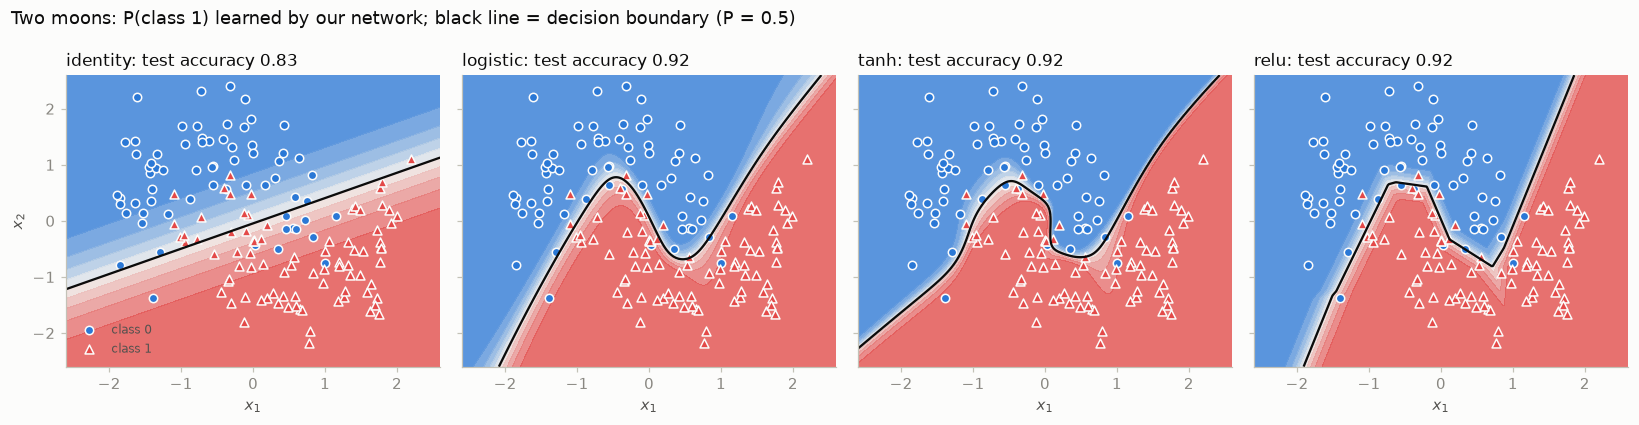

,ours,sklearn
hidden activation,,
identity,0.833 ± 0.000,0.831 ± 0.004
logistic,0.917 ± 0.004,0.915 ± 0.003
tanh,0.927 ± 0.007,0.923 ± 0.006
relu,0.919 ± 0.006,0.920 ± 0.000


In [14]:
X, y = make_moons(n_samples=500, noise=0.25, random_state=0)
moons = split_and_scale(X, y, test_size=0.3)
grid_x, grid_y = np.meshgrid(np.linspace(-2.6, 2.6, 300), np.linspace(-2.6, 2.6, 300))
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])

moons_rows = {}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
for ax, activation in zip(axes, ["identity", "logistic", "tanh", "relu"]):
    params = dict(hidden_layer_size=10, activation=activation, learning_rate=0.01, max_iter=2000, n_iter_no_change=2000)
    results, models = compare(SimpleSLPClassifier, params, moons)
    moons_rows[activation] = {"ours": f"{results['score ours'].mean():.3f} ± {results['score ours'].std():.3f}",
                              "sklearn": f"{results['score sklearn'].mean():.3f} ± {results['score sklearn'].std():.3f}"}
    model = models[0][0]
    proba = model.predict_proba(grid)[:, 1].reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, proba, levels=np.linspace(0, 1, 11), cmap=BLUE_RED, alpha=0.85)
    ax.contour(grid_x, grid_y, proba, levels=[0.5], colors=INK, linewidths=1.5)
    X_test, y_test = moons[1], moons[3]
    ax.scatter(*X_test[y_test == 0].T, s=30, marker="o", color=SERIES[0], edgecolor=SURFACE, linewidth=1, label="class 0")
    ax.scatter(*X_test[y_test == 1].T, s=34, marker="^", color=SERIES[7], edgecolor=SURFACE, linewidth=1, label="class 1")
    ax.set(title=f"{activation}: test accuracy {model.score(X_test, y_test):.2f}", xlabel="$x_1$")
    ax.grid(False)
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Two moons: P(class 1) learned by our network; black line = decision boundary (P = 0.5)",
             x=0.01, ha="left", color=INK)
plt.tight_layout()
plt.show()

moons_logistic = LogisticRegression().fit(moons[0], moons[2]).score(moons[1], moons[3])
SUMMARY.append({"dataset": "Two moons", "task": "binary classification", "metric": "accuracy",
                "baseline": f"{moons_logistic:.3f} (logistic regression)",
                "ours": moons_rows["tanh"]["ours"] + " (tanh)", "sklearn": moons_rows["tanh"]["sklearn"] + " (tanh)",
                "fit time ours (s)": "", "fit time sklearn (s)": ""})
pd.DataFrame(moons_rows).T.rename_axis("hidden activation")

**A plateau is not convergence.** With the default convergence check (patience 10, `tol=1e-4`), the *logistic* network stops after only about 100 epochs with the straight boundary of the identity network, and scikit-learn does exactly the same. With the factor-2 Glorot bound, logistic units start in their almost-linear region ($\sigma(z) \approx \tfrac12 + \tfrac z4$ for small $z$), so the network first finds the best *linear* boundary and then sits on a long, flat plateau. There the loss falls by less than `tol` per epoch, which is exactly what the convergence check is designed to detect. Only when the hidden weights have grown enough to leave the linear region does the boundary bend and the loss drop again.

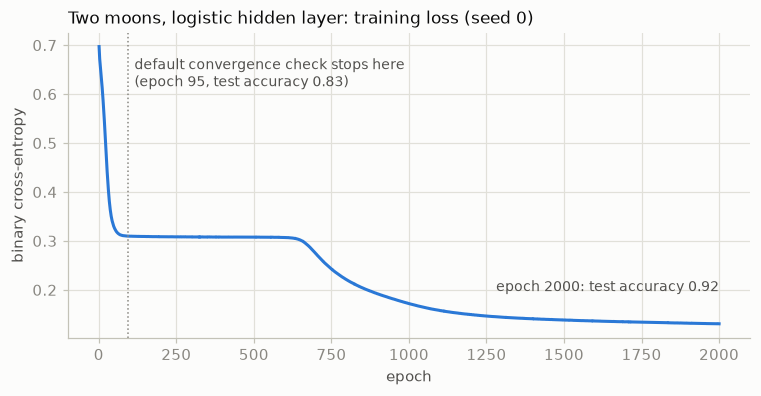

In [15]:
plateau = SimpleSLPClassifier(hidden_layer_size=10, activation="logistic", learning_rate=0.01,
                              max_iter=2000, n_iter_no_change=2000, random_state=0).fit(moons[0], moons[2])
stopped = SimpleSLPClassifier(hidden_layer_size=10, activation="logistic", learning_rate=0.01,
                              max_iter=2000, random_state=0).fit(moons[0], moons[2])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(1, 2001), plateau.loss_curve_, color=OURS)
ax.axvline(stopped.n_iter_, color=MUTED, linewidth=1, linestyle=":")
ax.text(stopped.n_iter_ + 20, max(plateau.loss_curve_) * 0.97,
        f"default convergence check stops here\n(epoch {stopped.n_iter_}, test accuracy {stopped.score(moons[1], moons[3]):.2f})",
        color=INK_2, fontsize=9, va="top")
ax.text(2000, plateau.loss_curve_[-1] + 0.06, f"epoch 2000: test accuracy {plateau.score(moons[1], moons[3]):.2f}",
        color=INK_2, fontsize=9, ha="right", va="bottom")
ax.set(title="Two moons, logistic hidden layer: training loss (seed 0)", xlabel="epoch", ylabel="binary cross-entropy")
plt.show()

## 8. Design experiments

### 8.1 Optimizers: SGD, SGD with momentum and Adam

All four runs below use breast cancer, 30 logistic hidden units, the default mini-batches of 200 (3 updates per epoch on the 455 training samples) and 200 epochs, with the convergence check disabled so the curves are complete. Each curve is the mean over 5 seeds.

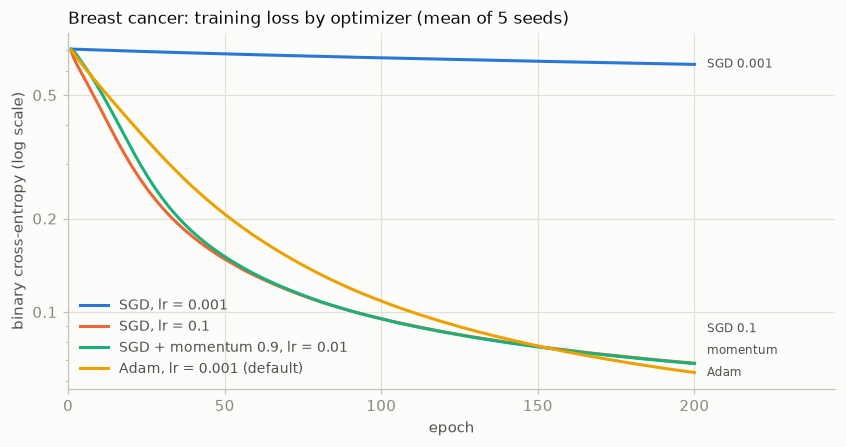

,loss after 20 epochs,loss after 200 epochs,test accuracy
"SGD, lr = 0.001",0.693,0.628,0.644 ± 0.019
"SGD, lr = 0.1",0.299,0.068,0.972 ± 0.007
"SGD + momentum 0.9, lr = 0.01",0.340,0.068,0.974 ± 0.006
"Adam, lr = 0.001 (default)",0.410,0.064,0.972 ± 0.004


In [16]:
optimizers = {
    "SGD, lr = 0.001": dict(solver="sgd", momentum=0.0, learning_rate=0.001),
    "SGD, lr = 0.1": dict(solver="sgd", momentum=0.0, learning_rate=0.1),
    "SGD + momentum 0.9, lr = 0.01": dict(solver="sgd", momentum=0.9, learning_rate=0.01),
    "Adam, lr = 0.001 (default)": dict(solver="adam", learning_rate=0.001),
}
fig, ax = plt.subplots(figsize=(9, 4.2))
optimizer_rows, ends = {}, []
for color, (name, params) in zip(SERIES, optimizers.items()):
    models = [SimpleSLPClassifier(hidden_layer_size=30, max_iter=200, n_iter_no_change=200, random_state=s, **params)
              .fit(cancer[0], cancer[2]) for s in SEEDS]
    curve = np.mean([m.loss_curve_ for m in models], axis=0)
    ax.plot(np.arange(1, 201), curve, color=color, label=name)
    ends.append(curve[-1])
    accs = [m.score(cancer[1], cancer[3]) for m in models]
    optimizer_rows[name] = {"loss after 20 epochs": curve[19], "loss after 200 epochs": curve[-1],
                            "test accuracy": f"{np.mean(accs):.3f} ± {np.std(accs, ddof=1):.3f}"}
plain_log_axis(ax)
ax.set_xlim(0, 245)
label_line_ends(ax, 204, ends, ["SGD 0.001", "SGD 0.1", "momentum", "Adam"])
ax.set(title="Breast cancer: training loss by optimizer (mean of 5 seeds)", xlabel="epoch", ylabel="binary cross-entropy (log scale)")
ax.legend(loc="lower left", fontsize=9)
plt.show()
pd.DataFrame(optimizer_rows).T.style.format({"loss after 20 epochs": "{:.3f}", "loss after 200 epochs": "{:.3f}"})

Plain SGD at learning rate 0.001 is far too slow. Adam reaches a low loss at the same nominal learning rate, because its per-weight step is about $\eta$, whatever the size of the gradient. SGD with a 100× larger learning rate, or with momentum (whose effective step is about $\eta/(1-\mu) = 10\eta$), closes the gap, and both are even faster than Adam for the first 150 epochs. Adam's advantage is that it works well at the default learning rate without any tuning. The cell below reruns the **provided** test `test_score` (binary data, 30 hidden units, default learning rate 0.001, 200 epochs, threshold 60%) with both solvers. This is why Adam is the default.

In [17]:
X, y = make_classification(n_samples=200, n_features=10, n_informative=8, n_redundant=2, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler().fit(X_train)
test_data = scaler.transform(X_train), scaler.transform(X_test), y_train, y_test
rows = {}
for solver in ["sgd", "adam"]:
    accs = [SimpleSLPClassifier(hidden_layer_size=30, max_iter=200, solver=solver, random_state=s)
            .fit(test_data[0], test_data[2]).score(test_data[1], test_data[3]) for s in [42, 0, 1, 2, 3]]
    rows[solver] = {"accuracy, random_state=42 (the test)": accs[0], "worst of 5 seeds": min(accs), "passes (> 0.6)": accs[0] > 0.6}
pd.DataFrame(rows).T

,"accuracy, random_state=42 (the test)",worst of 5 seeds,passes (> 0.6)
sgd,0.533333,0.4,False
adam,0.7,0.683333,True


### 8.2 Batch size: stochastic, mini-batch and full-batch gradient descent

The setup is breast cancer with Adam at learning rate 0.001 for 50 epochs. A smaller batch means more weight updates per epoch, so the loss falls faster **per epoch**. Each update is noisier, though, and the Python overhead per update makes small batches slower in wall-clock time. Every option is fully vectorised *within* a batch.

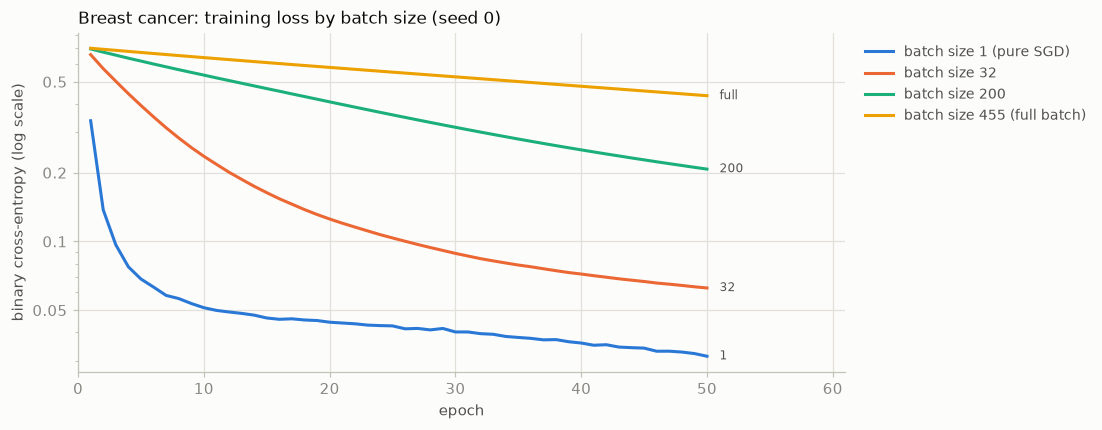

,updates per epoch,fit time (s),final training loss,test accuracy
batch size,,,,
1 (pure SGD),455.000000,0.89,0.0314,0.982
32,15.000000,0.04,0.0626,0.974
200,3.000000,0.02,0.2074,0.947
455 (full batch),1.000000,0.01,0.4346,0.895


In [18]:
n_train = len(cancer[0])
batch_rows, ends = {}, []
fig, ax = plt.subplots(figsize=(9, 4))
for color, batch_size in zip(SERIES, [1, 32, 200, n_train]):
    model = SimpleSLPClassifier(hidden_layer_size=30, batch_size=batch_size, max_iter=50, n_iter_no_change=50, random_state=0)
    seconds = fit_timed(model, cancer[0], cancer[2])
    label = {1: "1 (pure SGD)", n_train: f"{n_train} (full batch)"}.get(batch_size, str(batch_size))
    ax.plot(np.arange(1, 51), model.loss_curve_, color=color, label=f"batch size {label}")
    ends.append(model.loss_curve_[-1])
    batch_rows[label] = {"updates per epoch": int(np.ceil(n_train / batch_size)), "fit time (s)": seconds,
                         "final training loss": model.loss_curve_[-1], "test accuracy": model.score(cancer[1], cancer[3])}
plain_log_axis(ax)
ax.set_xlim(0, 61)
label_line_ends(ax, 51, ends, ["1", "32", "200", "full"])
ax.set(title="Breast cancer: training loss by batch size (seed 0)", xlabel="epoch", ylabel="binary cross-entropy (log scale)")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
pd.DataFrame(batch_rows).T.rename_axis("batch size").style.format(
    {"fit time (s)": "{:.2f}", "final training loss": "{:.4f}", "test accuracy": "{:.3f}"})

### 8.3 Weight initialisation: Glorot vs $\mathcal N(0, 0.01^2)$

The scaffold suggests initialising weights from $\mathcal N(0, 0.01^2)$. To measure the effect without adding a parameter to the library, I override `_initialize_weights` in a small subclass. The setup is breast cancer, 30 hidden units, Adam with learning rate 0.001 and 100 epochs, averaged over 5 seeds.

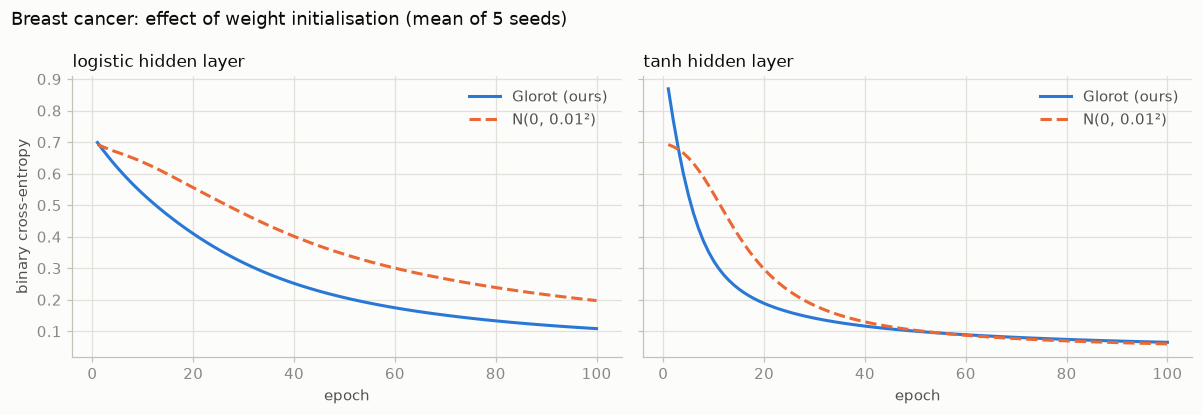

In [19]:
class SmallInitClassifier(SimpleSLPClassifier):
    # Same model, but weights drawn from N(0, 0.01^2) as suggested in the scaffold.
    def _initialize_weights(self):
        self.W1_ = self._rng.normal(0.0, 0.01, (self.n_features_in_, self.hidden_layer_size))
        self.b1_ = np.zeros(self.hidden_layer_size)
        self.W2_ = self._rng.normal(0.0, 0.01, (self.hidden_layer_size, self.n_outputs_))
        self.b2_ = np.zeros(self.n_outputs_)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
init_rows = {}
for ax, activation in zip(axes, ["logistic", "tanh"]):
    for color, linestyle, (name, cls) in zip(SERIES, ["-", "--"], [("Glorot (ours)", SimpleSLPClassifier),
                                                                   ("N(0, 0.01²)", SmallInitClassifier)]):
        models = [cls(hidden_layer_size=30, activation=activation, max_iter=100, n_iter_no_change=100, random_state=s)
                  .fit(cancer[0], cancer[2]) for s in SEEDS]
        curve = np.mean([m.loss_curve_ for m in models], axis=0)
        ax.plot(np.arange(1, 101), curve, color=color, linestyle=linestyle, label=name)
        init_rows[(activation, name)] = {"loss after 10 epochs": curve[9], "loss after 100 epochs": curve[-1],
                                         "test accuracy": np.mean([m.score(cancer[1], cancer[3]) for m in models])}
    ax.set(title=f"{activation} hidden layer", xlabel="epoch")
    ax.legend()
axes[0].set_ylabel("binary cross-entropy")
fig.suptitle("Breast cancer: effect of weight initialisation (mean of 5 seeds)", x=0.01, ha="left", color=INK)
plt.tight_layout()
plt.show()
pd.DataFrame(init_rows).T.style.format("{:.3f}")

With weights of size 0.01, every hidden unit starts in the near-linear region around $z_1 \approx 0$, and the gradient reaching $W_1$ is scaled by $W_2 \approx 0.01$. The loss therefore stays near $\log 2 \approx 0.693$, the loss of a constant guess of 0.5, for the first epochs. With one hidden layer, Adam eventually catches up. In deeper networks the shrinking factor is multiplied once per layer, and too-small initialisation can stall training completely, which is why Glorot initialisation was introduced.

### 8.4 Target scaling in the regressor

My regressor standardises $y$ internally. To show what happens without this step, I train scikit-learn's `MLPRegressor`, which does **not** scale $y$, with and without a `StandardScaler` on the target. I use two settings: diabetes as in Section 4, and the provided test `test_score` (`make_regression` data, whose target has a standard deviation in the hundreds).

In [20]:
X, y = make_regression(n_samples=200, n_features=10, n_informative=8, noise=10.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler().fit(X_train)
synthetic = scaler.transform(X_train), scaler.transform(X_test), y_train, y_test

experiments = {
    f"diabetes, Section 4 settings (y std = {diabetes[2].std():.0f})":
        (diabetes, dict(hidden_layer_size=20, learning_rate=0.01, max_iter=1000, early_stopping=True)),
    f"make_regression, settings of the provided test_score (y std = {y_train.std():.0f})":
        (synthetic, dict(hidden_layer_size=30, learning_rate=0.01, max_iter=300)),
}
scaling_rows = {}
for name, (data, params) in experiments.items():
    results = {"sklearn, raw y": [], "sklearn, standardised y": [], "ours (standardises internally)": []}
    for seed in SEEDS:
        ours = SimpleSLPRegressor(**params, random_state=seed)
        scaled = sklearn_twin(ours)        # MLPRegressor inside a TransformedTargetRegressor
        raw = clone(scaled.regressor)      # the same MLPRegressor, trained on the raw target
        for column, model, network in [("sklearn, raw y", raw, lambda m: m), ("sklearn, standardised y", scaled, sklearn_network),
                                       ("ours (standardises internally)", ours, lambda m: m)]:
            model.fit(data[0], data[2])
            results[column].append((model.score(data[1], data[3]), network(model).n_iter_))
    scaling_rows[name] = {column: f"{np.mean([r for r, _ in v]):.3f} ({np.mean([e for _, e in v]):.0f} epochs)"
                          for column, v in results.items()}
pd.DataFrame(scaling_rows).T

,"sklearn, raw y","sklearn, standardised y",ours (standardises internally)
"diabetes, Section 4 settings (y std = 78)",0.345 (946 epochs),0.329 (40 epochs),0.337 (38 epochs)
"make_regression, settings of the provided test_score (y std = 155)",0.381 (300 epochs),0.983 (59 epochs),0.978 (45 epochs)


The table shows test R², with the mean number of epochs actually run in brackets. On diabetes, scikit-learn without target scaling ends at a similar R², but it needs about **950 epochs instead of 40**. The output weights have to grow until the network's output reaches the scale of $y$ (std 78), while Adam moves each weight by only about $\eta$ per step. On the provided test's data ($y$ std ≈ 160), the 300-epoch budget runs out first, at R² ≈ 0.38, which is below that test's threshold of 0.5. With a standardised target the network only has to produce values of order 1, and it converges in 40–60 epochs.

## 9. Summary

In [21]:
pd.DataFrame(SUMMARY).set_index("dataset")

,task,metric,baseline,ours,sklearn,fit time ours (s),fit time sklearn (s)
dataset,,,,,,,
Diabetes,regression,R²,0.332 (linear regression),0.337 ± 0.022,0.329 ± 0.027,0.01,0.01
Breast cancer,binary classification,accuracy,0.982 (logistic regression),0.982 ± 0.000,0.982 ± 0.000,0.09,0.10
Digits,10-class classification,accuracy,0.967 (logistic regression),0.976 ± 0.001,0.977 ± 0.004,0.15,0.23
Iris,3-class classification,accuracy,0.967 (logistic regression),1.000 ± 0.000,1.000 ± 0.000,0.01,0.02
California housing,regression,R²,0.594 (linear regression),0.742 ± 0.024,0.774 ± 0.006,1.08,1.63
Two moons,binary classification,accuracy,0.827 (logistic regression),0.927 ± 0.007 (tanh),0.923 ± 0.006 (tanh),,


### Conclusions

**The implementation is correct.**
* The analytic gradients match finite differences to about $10^{-8}$ for every combination of output layer and activation (Section 3).
* The 54 provided tests and 64 additional ones pass.
* On every dataset, our loss curves follow scikit-learn's almost exactly. That is what you would expect from the same algorithm run with different random numbers.

**It performs like scikit-learn.**
* With identical settings, our test score is within about one standard deviation of scikit-learn's on every dataset: breast cancer 0.982 vs 0.982, digits 0.976 vs 0.977, iris 1.000 vs 1.000, diabetes 0.337 vs 0.329, and two moons (tanh) 0.927 vs 0.923.
* California Housing looked like an exception with 5 seeds (0.742 vs 0.774). Over 20 seeds the two are equal (0.756 vs 0.760), and the variance comes from a few extreme test districts (Section 7.1).
* Fit times are similar. Ours is usually slightly faster on these small networks because it does less bookkeeping per epoch.

**What mattered most**
* **The non-linearity of the hidden layer.** On two moons, the identity network is stuck at 83% while every non-linear activation reaches about 92%. On California Housing, R² rises from 0.59 (linear) to about 0.76.
* **Early stopping on small, noisy data.** On diabetes, test R² is 0.206 after 300 epochs and 0.337 with early stopping. Only the second beats linear regression (0.332): the network has more capacity than 353 noisy samples can support.
* **Optimizer, learning rate and batch size together.** At the default learning rate of 0.001, plain SGD fails (64% on breast cancer, and it fails the provided `test_score`), while Adam reaches 97%. Smaller batches make more updates per epoch, which costs wall-clock time but gives more progress per epoch.
* **Initialisation and target scaling.** These mostly affect speed. $\mathcal N(0, 0.01^2)$ weights slow down the first epochs, and an unscaled target makes the regressor need about 950 epochs instead of 40.

**Limitations and possible extensions**
* There is only one hidden layer; the "arbitrary depth" bonus is not implemented. The shared backpropagation code would generalise naturally to a loop over a list of layers.
* There is no L2 regularisation (scikit-learn's `alpha`) and no learning-rate schedule. Regularisation would probably help on diabetes.
* The early-stopping split is random rather than stratified. It also monitors the validation *loss*, whereas scikit-learn monitors the validation *score* (accuracy or R²).
* ReLU networks extrapolate linearly, so inputs far outside the training range, as in California Housing, should be clipped or log-transformed first.